# Análisis de series temporales: ejercicio 2

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import kpss, adfuller
from statsmodels.stats.diagnostic import het_arch

El archivo "serie_temporal.csv" contiene datos de la evolución  de cierto fenómeno atmosférico. Se pide, descomponer ([seasonal_decompose](https://www.statsmodels.org/dev/generated/statsmodels.tsa.seasonal.seasonal_decompose.html)) la serie temporal. Para ello, debereis decidir que tipo de descomposición requiere  y representar la descomposición para su visualización.
Responde a las siguientes preguntas:

- ¿Qué tipo de descomposición has aplicado? ¿Por qué? 
- ¿Presenta tendencia la serie temporal? En caso afirmativo, ¿cómo es la tendencia?
- ¿Es estacional la serie temporal? En caso afirmatico ¿cuál es el periodo de la componente estacional?
- ¿Se detectan puntos de impacto? En caso afirmativo indica en que instante temporal se encuentran.
- ¿Es estrictamente estacionario el residuo de la serie? Para ello, tendréis que hacer uso de los test estadísticos de Augmented Dickey Fuller ([ADF](https://www.statsmodels.org/dev/generated/statsmodels.tsa.stattools.adfuller.html)) y  Kwiatkowski-Phillips-Schmidt-Shin ([KPSS](https://www.statsmodels.org/dev/generated/statsmodels.tsa.stattools.kpss.html#statsmodels.tsa.stattools.kpss)) que permiten comprobar la estacionariedad de primer orden en series temporales. Además, deberéis de hacer uso de los test de heterocedasticidad para saber si es estacionario en varianza.

Para saber el número de puntos que tiene un cierto intervalo temporal, y poder así hacer una mejor definición del periodo de la componente estacional, se puede hacer uso de la librería [pandas.DaraFrame.resample](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.resample.html).

In [2]:
data = pd.read_csv("serie_temporal.csv", header=0, parse_dates=[0], index_col=[0])
data.head()

,Value
Date,
2020-01-01,152.000000
2020-01-02,150.905913
2020-01-03,81.804686
2020-01-04,182.689188
2020-01-05,156.552301


<Axes: xlabel='Date'>

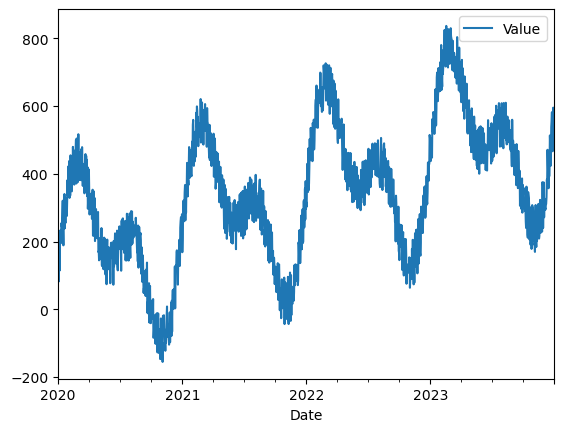

In [3]:
data.plot()

In [4]:
# Número de puntos por año y frecuencia
print(data["Value"].resample("YS").count())
print("Frecuencia:", pd.infer_freq(data.index))

# ¿Hay valores <= 0? (si los hay, no se puede usar el modelo multiplicativo)
print("Valores <= 0:", (data["Value"] <= 0).sum())

# ¿La amplitud crece con el nivel? (si no crece -> aditivo)
nivel = data["Value"].rolling(365, center=True).mean()
disp = data["Value"].rolling(365, center=True).std()
print("Correlación nivel-dispersión:", nivel.corr(disp))

Date
2020-01-01    366
2021-01-01    365
2022-01-01    365
2023-01-01    365
Freq: YS-JAN, Name: Value, dtype: int64
Frecuencia: D
Valores <= 0: 70
Correlación nivel-dispersión: -0.02616404174298876


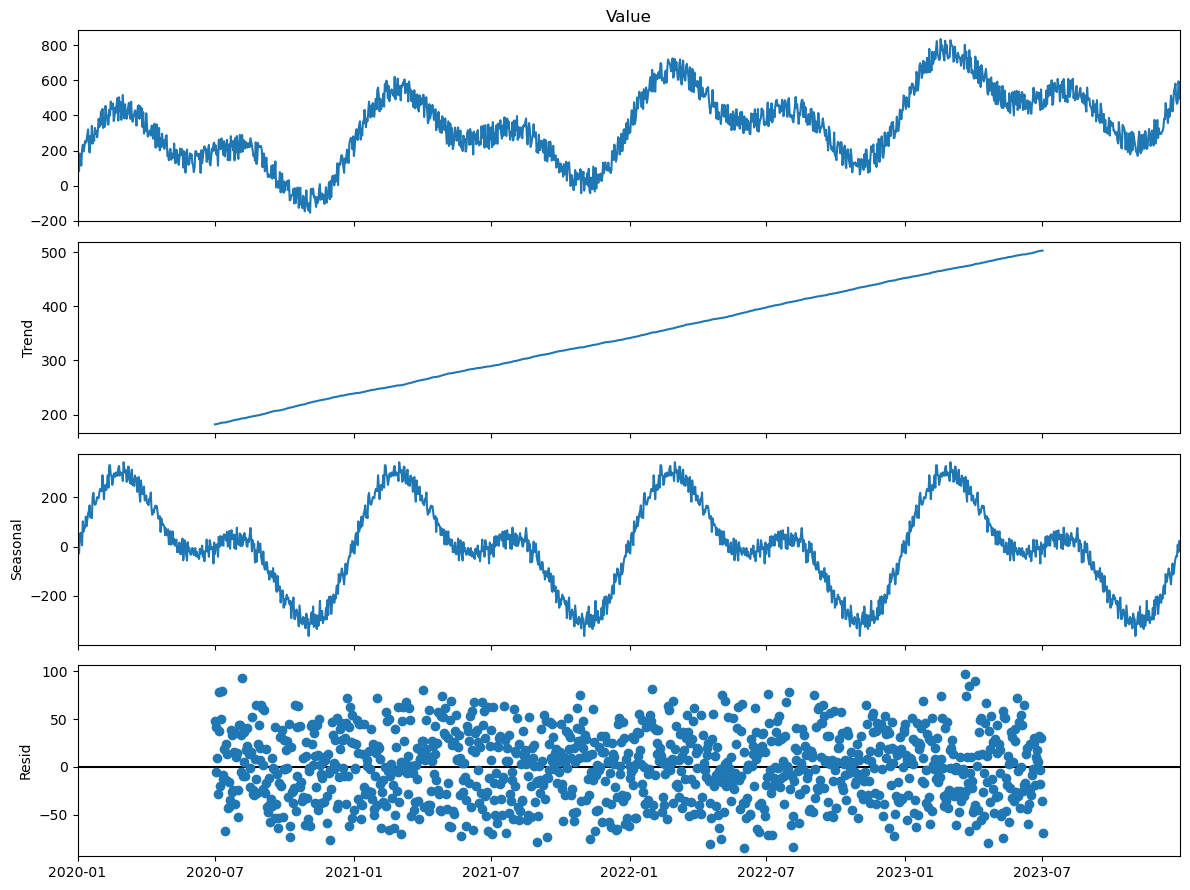

In [5]:
periodo = 365  # datos diarios, ciclo anual
dec = seasonal_decompose(data["Value"], model="additive", period=periodo)

fig = dec.plot()
fig.set_size_inches(12, 9)
plt.tight_layout()
plt.show()

In [6]:
#tendencia
from scipy import stats

trend = dec.trend.dropna()
x = np.arange(len(trend))
pend, interc, r, p, _ = stats.linregress(x, trend.values)
print(f"Pendiente: {pend:.4f} unidades/día ({pend*365:.1f} por año), R2={r**2:.3f}")

print(data["Value"].groupby(data.index.year).mean())

Pendiente: 0.2929 unidades/día (106.9 por año), R2=1.000
Date
2020    182.116120
2021    289.471233
2022    398.308219
2023    502.863014
Name: Value, dtype: float64


## Estacionalidad

Amplitud estacional: 706.5539568636684
Máximo estacional: 02-mar.
Mínimo estacional: 02-nov.
Fuerza estacionalidad: 0.961 | Fuerza tendencia: 0.869


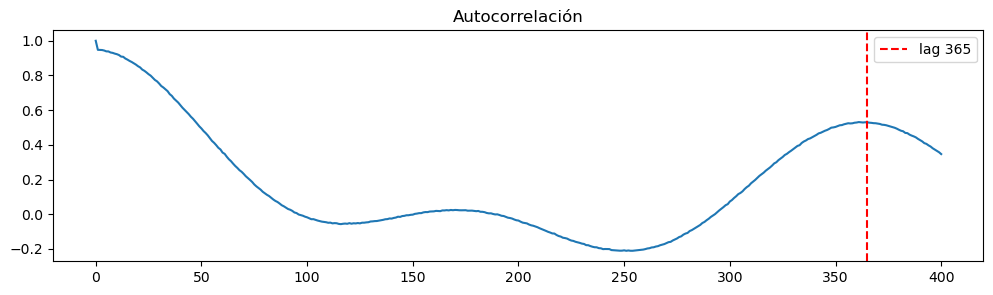

ACF en lag 365: 0.530207073242266


In [7]:
#estacionalidad
from statsmodels.tsa.stattools import acf

ciclo = dec.seasonal.iloc[:periodo]
print("Amplitud estacional:", ciclo.max() - ciclo.min())
print("Máximo estacional:", ciclo.idxmax().strftime("%d-%b"))
print("Mínimo estacional:", ciclo.idxmin().strftime("%d-%b"))

resid = dec.resid.dropna()
Fs = max(0, 1 - resid.var() / (dec.seasonal.loc[resid.index] + resid).var())
Ft = max(0, 1 - resid.var() / (dec.trend.loc[resid.index] + resid).var())
print(f"Fuerza estacionalidad: {Fs:.3f} | Fuerza tendencia: {Ft:.3f}")

ac = acf(data["Value"], nlags=400, fft=True)
plt.figure(figsize=(12, 3))
plt.plot(ac)
plt.axvline(365, color="r", ls="--", label="lag 365")
plt.legend()
plt.title("Autocorrelación")
plt.show()
print("ACF en lag 365:", ac[365])

Outliers en el residuo: 0
Series([], Name: resid, dtype: float64)
Saltos bruscos (|z|>4): 0


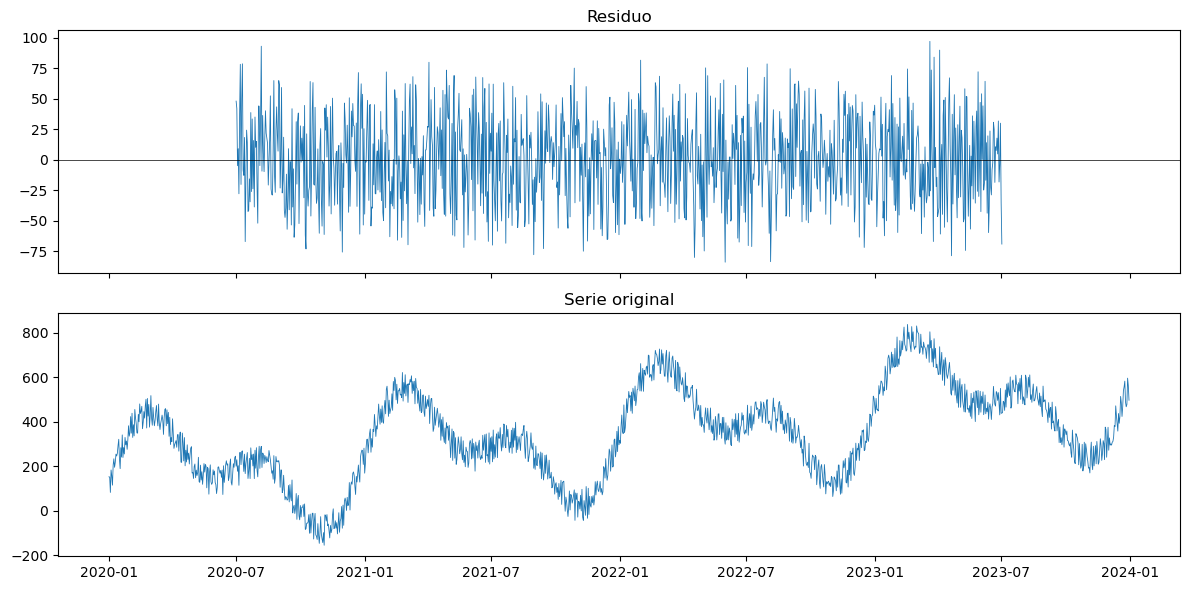

In [8]:
#puntos de impacto

# Outliers en el residuo (z robusto con MAD)
mad = np.median(np.abs(resid - resid.median())) * 1.4826
z = (resid - resid.median()) / mad
outliers = resid[z.abs() > 3.5]
print("Outliers en el residuo:", len(outliers))
print(outliers)

# Saltos bruscos en la serie original
d1 = data["Value"].diff().dropna()
zd = (d1 - d1.median()) / (np.median(np.abs(d1 - d1.median())) * 1.4826)
print("Saltos bruscos (|z|>4):", (zd.abs() > 4).sum())

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(resid, lw=0.6)
ax[0].scatter(outliers.index, outliers.values, color="r", s=15)
ax[0].axhline(0, color="k", lw=0.5)
ax[0].set_title("Residuo")
ax[1].plot(data["Value"], lw=0.6)
ax[1].set_title("Serie original")
plt.tight_layout()
plt.show()

### Estacionariedad

C:\Users\maren\AppData\Local\Temp\ipykernel_11352\1414544338.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_res = adfuller(resid, autolag="AIC")
C:\Users\maren\AppData\Local\Temp\ipykernel_11352\1414544338.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_stat, kpss_p, kpss_lags, kpss_crit = kpss(resid, regression="c", nlags="auto")
C:\Users\maren\AppData\Local\Temp\ipykernel_11352\1414544338.py:7: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when sto

ADF: estadístico=-34.620, p-valor=0, retardos=0
Valores críticos: {'1%': -3.4363305491063763, '5%': -2.864180690211292, '10%': -2.5681759880987265}
KPSS: estadístico=0.031, p-valor=0.1, retardos=1
Valores críticos: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}
=> Residuo ESTACIONARIO en media
ARCH-LM: LM=10.258, p-valor=0.5933
Varianza del residuo por año:
Date
2020    1302.527511
2021    1323.823565
2022    1214.067742
2023    1353.839366
Name: resid, dtype: float64


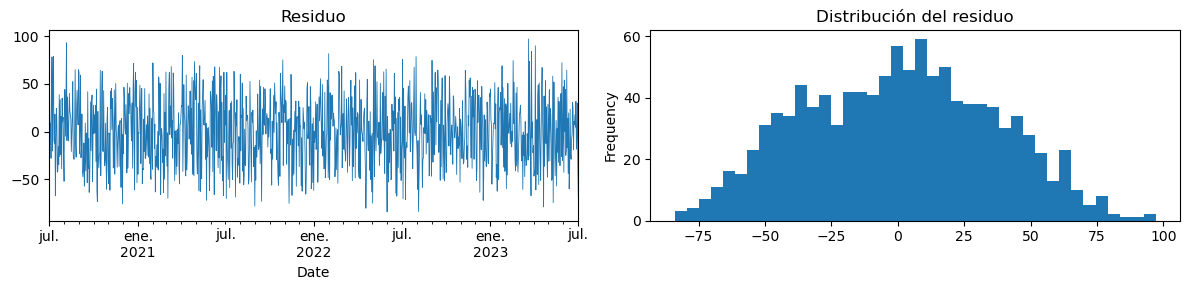

In [9]:

# --- ADF (H0: raíz unitaria, no estacionaria) ---
adf_res = adfuller(resid, autolag="AIC")
print(f"ADF: estadístico={adf_res[0]:.3f}, p-valor={adf_res[1]:.4g}, retardos={adf_res[2]}")
print("Valores críticos:", adf_res[4])

# --- KPSS (H0: estacionaria en nivel) ---
kpss_stat, kpss_p, kpss_lags, kpss_crit = kpss(resid, regression="c", nlags="auto")
print(f"KPSS: estadístico={kpss_stat:.3f}, p-valor={kpss_p:.4g}, retardos={kpss_lags}")
print("Valores críticos:", kpss_crit)

if adf_res[1] < 0.05 and kpss_p >= 0.05:
    print("=> Residuo ESTACIONARIO en media")
elif adf_res[1] >= 0.05 and kpss_p < 0.05:
    print("=> Residuo NO estacionario en media")
else:
    print("=> Resultados contradictorios")

# --- Heterocedasticidad (H0: homocedasticidad) ---
lm, lm_p, f, f_p = het_arch(resid, nlags=12)
print(f"ARCH-LM: LM={lm:.3f}, p-valor={lm_p:.4f}")

print("Varianza del residuo por año:")
print(resid.groupby(resid.index.year).var())

fig, ax = plt.subplots(1, 2, figsize=(12, 3))
resid.plot(ax=ax[0], lw=0.6, title="Residuo")
resid.plot(kind="hist", bins=40, ax=ax[1], title="Distribución del residuo")
plt.tight_layout()
plt.show()